# 04 · Feature Engineering
**CRISP-DM Phase 3 — Data Preparation**

| # | Step | Decision it finalizes |
|---|---|---|
| 1 | Confirm the label | 1D horizon, θ = 1% (recommended in `03_eda.ipynb`, item 11) |
| 2 | Create candidate features | Mathematical transformations, domain ratios, date/time, interactions |
| 3 | Chronological split | Train/val/test **before** any selection, so selection only sees train |
| 4 | Curse of dimensionality | How many features the training set can support |
| 5 | Feature selection | Correlation heatmap, feature vs target, ANOVA + MI, filter pass |
| 6 | Feature extraction (PCA) | Where the redundancy sits; a PCA variant for comparison |
| 7 | Persist | Parquet splits + the tracked manifest `src/features/selected_features.json` |

> ⚠️ **Leakage rules.** Every feature for row *t* uses data up to and including `close[t]` only
> (see `src/features/returns.py`); the label at *t* looks forward to `close[t + horizon]`. The split
> stays chronological with the boundary rows purged. **New in this version:** every selection and
> extraction step is fit on `train` only — choosing features by looking at val/test would leak the
> evaluation data into the model just as surely as fitting a scaler on test.

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from notebooks/ or the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.features.engineering import (FLAT_THRESHOLD, LABEL_HORIZON, build_features,
                                      chronological_split)
from src.features.returns import DOWN, FLAT, UP
from src.features.selection import (CORR_THRESHOLD, MANIFEST_PATH, correlated_pairs, fit_pca,
                                    low_variance, near_constant, pca_transform, relevance,
                                    save_manifest, select_features)
from src.visualization.style import (BLUE, CLASS_COLORS, DIVERGING, NEUTRAL, TEXT_SECONDARY,
                                     apply_style, save)

apply_style()
CLASS_NAMES = {DOWN: "down", FLAT: "flat", UP: "up"}

raw_1d = pd.read_parquet(config.INTERIM_DIR / f"{config.SYMBOL.lower()}_1D_clean.parquet")
print(f"{len(raw_1d):,} daily candles, {raw_1d.index.min().date()} -> {raw_1d.index.max().date()}")

3,332 daily candles, 2017-08-17 -> 2026-09-30


## 1 · Confirm the label

UP if the next day's log return is above +1 %, DOWN if below −1 %, FLAT otherwise — unchanged from
EDA item 11. Keeping the label fixed is deliberate: this notebook changes the *features*, and changing
the target at the same time would make it impossible to tell which change moved the results.

## 2 · Create candidate features

`build_features` creates every candidate and attaches the label, in five families:

| Family | Columns | Why |
|---|---|---|
| **Mathematical transformations** | `ret_lag1..3` (true lags of the 1-day log return), `mom_7d/14d/30d` (cumulative log return), `vol_7d/14d/30d` (rolling std), `atr_14` / close | Log returns make price changes additive and scale-free; dividing ATR by close makes it comparable across a $3k and a $100k bitcoin |
| **Aggregations** | the rolling windows above, `volume_z` (14-day z-score of log volume), `volume_ratio` (volume / 30-day mean) | Recent history summarised back onto each row |
| **Domain knowledge** | `dist_ma20`, `dist_ma50` (close / MA − 1), `vol_ratio` (vol_7d / vol_30d), `rsi_14`, `taker_buy_ratio` | Trend position, whether volatility is expanding, overbought/oversold, buy-pressure — standard trader signals |
| **Date / time** | `dow_sin`, `dow_cos`, `is_weekend` | BTC trades 24/7 and weekend liquidity is thinner; sin/cos keeps Sunday next to Monday |
| **Interactions** | `ret1_x_volz` (yesterday's move × its volume surprise), `mom7_x_volratio` (trend × volatility regime) | A big move on huge volume may mean something different from the same move on quiet volume |

**Removed on domain grounds: `log_volume`.** The raw volume level trends upward over the years, so the
values a tree learns to split on in 2017–2024 never reappear later — a decision a statistical test on
train alone cannot catch, since train is where those levels *do* exist. Only relative volume measures
are kept. (The former `ret_lag5/7/14` were really overlapping 5/7/14-day cumulative returns; that
information now lives in the honestly-named `mom_*` columns.)

In [3]:
features = build_features(raw_1d, horizon=LABEL_HORIZON, flat_threshold=FLAT_THRESHOLD)
candidate_cols = [c for c in features.columns if c != "label"]
assert np.isfinite(features[candidate_cols].to_numpy()).all(), "no NaN/inf allowed in model-ready features"

print(f"{len(candidate_cols)} candidate features")
print(f"{len(features):,} model-ready rows ({len(raw_1d) - len(features)} dropped to warm-up windows, "
      f"data gaps and the trailing horizon)")
features.head()

22 candidate features
2,793 model-ready rows (539 dropped to warm-up windows, data gaps and the trailing horizon)


,ret_lag1,ret_lag2,ret_lag3,mom_7d,mom_14d,mom_30d,vol_7d,vol_14d,vol_30d,atr_14,...,rsi_14,volume_z,volume_ratio,taker_buy_ratio,dow_sin,dow_cos,is_weekend,ret1_x_volz,mom7_x_volratio,label
open_time,,,,,,,,,,,,,,,,,,,,,
2017-10-26 00:00:00+00:00,0.029743,0.038146,-0.077086,0.030814,0.076512,0.412011,0.043693,0.036224,0.036754,0.065428,...,63.545786,0.498298,1.559398,0.395212,0.433884,-0.900969,0,0.014821,0.036632,-1.0
2017-10-27 00:00:00+00:00,-0.015982,0.029743,0.038146,-0.040957,0.020817,0.319053,0.037625,0.035218,0.035121,0.064804,...,60.867804,-0.716546,1.087250,0.444600,-0.433884,-0.900969,0,0.011452,-0.043877,0.0
2017-10-28 00:00:00+00:00,-0.008563,-0.015982,0.029743,-0.052007,-0.025947,0.314911,0.037448,0.033651,0.035190,0.064112,...,59.440032,-1.333729,0.978136,0.409192,-0.974928,-0.222521,1,0.011421,-0.055343,1.0
2017-10-29 00:00:00+00:00,0.075790,-0.008563,-0.015982,0.036301,0.077478,0.390655,0.048648,0.038551,0.037081,0.059659,...,67.058432,0.096298,1.375548,0.528691,-0.781831,0.623490,1,0.007298,0.047625,0.0
2017-10-30 00:00:00+00:00,-0.008052,0.075790,-0.008563,0.033995,0.060703,0.334935,0.048742,0.038705,0.036679,0.060316,...,65.600468,-0.820898,1.102107,0.385518,0.000000,1.000000,0,0.006610,0.045175,1.0


The longest window (the 50-day moving average) sets the warm-up, and every unfilled data gap costs
another 50 rows after it — that is why more rows are dropped than in the previous 30-day-window version.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


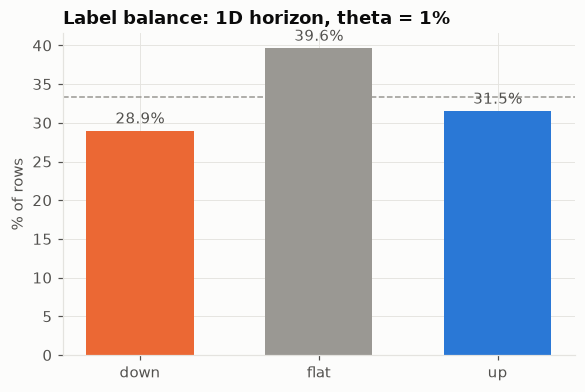

In [4]:
shares = features["label"].value_counts(normalize=True).rename(CLASS_NAMES).reindex(["down", "flat", "up"])

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(shares.index, 100 * shares.values, color=[CLASS_COLORS[c] for c in shares.index], width=0.6)
ax.axhline(100 / 3, color=NEUTRAL, linestyle="--", linewidth=1)
ax.set(title="Label balance: 1D horizon, theta = 1%", ylabel="% of rows")
for x, v in enumerate(shares.values):
    ax.text(x, 100 * v + 1, f"{100 * v:.1f}%", ha="center", color=TEXT_SECONDARY)
save(fig, "04_label_balance")
plt.show()

## 3 · Chronological train / validation / test split

A 70/15/15 split by time, never shuffled. `embargo=LABEL_HORIZON` drops the last row(s) of `train` and
`val` whose label would otherwise be computed from a close price inside the next split.
**From here on, every decision about features is made on `train` only.**

In [5]:
train, val, test = chronological_split(features, train_frac=0.7, val_frac=0.15, embargo=LABEL_HORIZON)
X_train, y_train = train[candidate_cols], train["label"]

assert train.index.max() < val.index.min() < val.index.max() < test.index.min(), "splits must not overlap"
assert len(train) + len(val) + len(test) == len(features) - 2 * LABEL_HORIZON

pd.DataFrame({
    split: {"rows": len(df), "start": df.index.min().date(), "end": df.index.max().date()}
    for split, df in [("train", train), ("val", val), ("test", test)]
}).T

,rows,start,end
train,1954,2017-10-26,2024-06-12
val,417,2024-06-14,2025-08-04
test,420,2025-08-06,2026-09-29


## 4 · The curse of dimensionality

Each extra feature adds a dimension, and the volume of the feature space grows exponentially while the
number of training rows stays fixed — so the data gets sparser and models find spurious patterns more
easily. The check below puts the candidate set in perspective.

In [6]:
n_rows, n_feats = len(train), len(candidate_cols)
print(f"train rows: {n_rows:,} | candidate features: {n_feats} | rows per feature: {n_rows / n_feats:.0f}")
print(f"rows per feature per class: {n_rows / n_feats / 3:.0f}")

train rows: 1,954 | candidate features: 22 | rows per feature: 89
rows per feature per class: 30


About 90 rows per feature is not extreme by textbook standards, but it is thin for this problem:
the signal in daily BTC direction is weak (Phase 4 found no feature set beating persistence), and a
weak signal needs *more* data per feature to separate from noise, not less. That is the case for
fighting back with both standard tools — **selection** (section 5, keeps original features, stays
interpretable) and **extraction** (section 6, PCA, compresses everything into fewer new axes).

## 5 · Feature selection

### 5.1 Correlation heatmap

A first pass for redundancy. **Spearman** (rank) correlation instead of Pearson, because BTC returns are
fat-tailed: a handful of crash days would otherwise dominate the coefficient. Computed on `train` only.

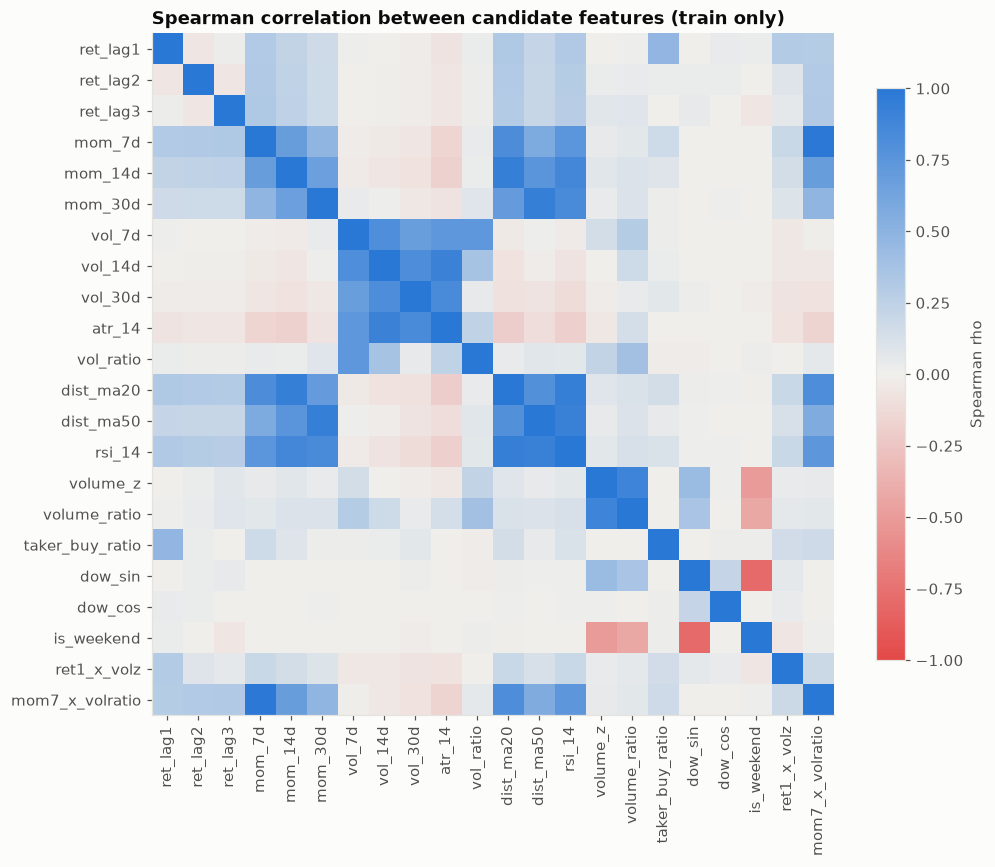

,a,b,corr
0,mom_7d,mom7_x_volratio,0.99
3,mom_30d,dist_ma50,0.93
1,mom_14d,dist_ma20,0.93
5,dist_ma20,rsi_14,0.93
6,dist_ma50,rsi_14,0.92
4,vol_14d,atr_14,0.91
7,volume_z,volume_ratio,0.89
2,mom_14d,rsi_14,0.87


In [7]:
corr_train = X_train.corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr_train, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(n_feats), candidate_cols, rotation=90)
ax.set_yticks(range(n_feats), candidate_cols)
ax.grid(False)
ax.set_title("Spearman correlation between candidate features (train only)")
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman rho")
save(fig, "04_feature_correlation")
plt.show()

correlated_pairs(corr_train, CORR_THRESHOLD).round(2)

The table lists every pair above the |ρ| > 0.85 cut used in the filter pass (5.4). Three blocks stand out
in the heatmap:

* **Trend** — `mom_*`, `dist_ma*` and `rsi_14` all measure "how far above its recent past is the price",
  so they correlate at 0.87–0.93. `mom7_x_volratio` correlates 0.99 with `mom_7d`: `vol_ratio` hovers
  around 1, so multiplying by it barely changes the momentum — an interaction that adds almost nothing.
* **Volatility** — `vol_*` and `atr_14` (`vol_14d` vs `atr_14` at 0.91).
* **Volume / calendar** — `volume_z` vs `volume_ratio` (0.89), and both are lower on weekends (the
  negative link to `is_weekend`): the market is quieter on Saturdays and Sundays.

The true lags `ret_lag1..3` are almost uncorrelated with each other — the fix for the old overlapping
`ret_lag5/7/14` columns worked.

### 5.2 Feature vs target

Each panel shows one feature's distribution within each label class (outliers hidden, so the boxes stay
readable despite fat tails). A feature that helps tell UP from DOWN shows boxes at different heights; boxes
that line up exactly carry no information on their own.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


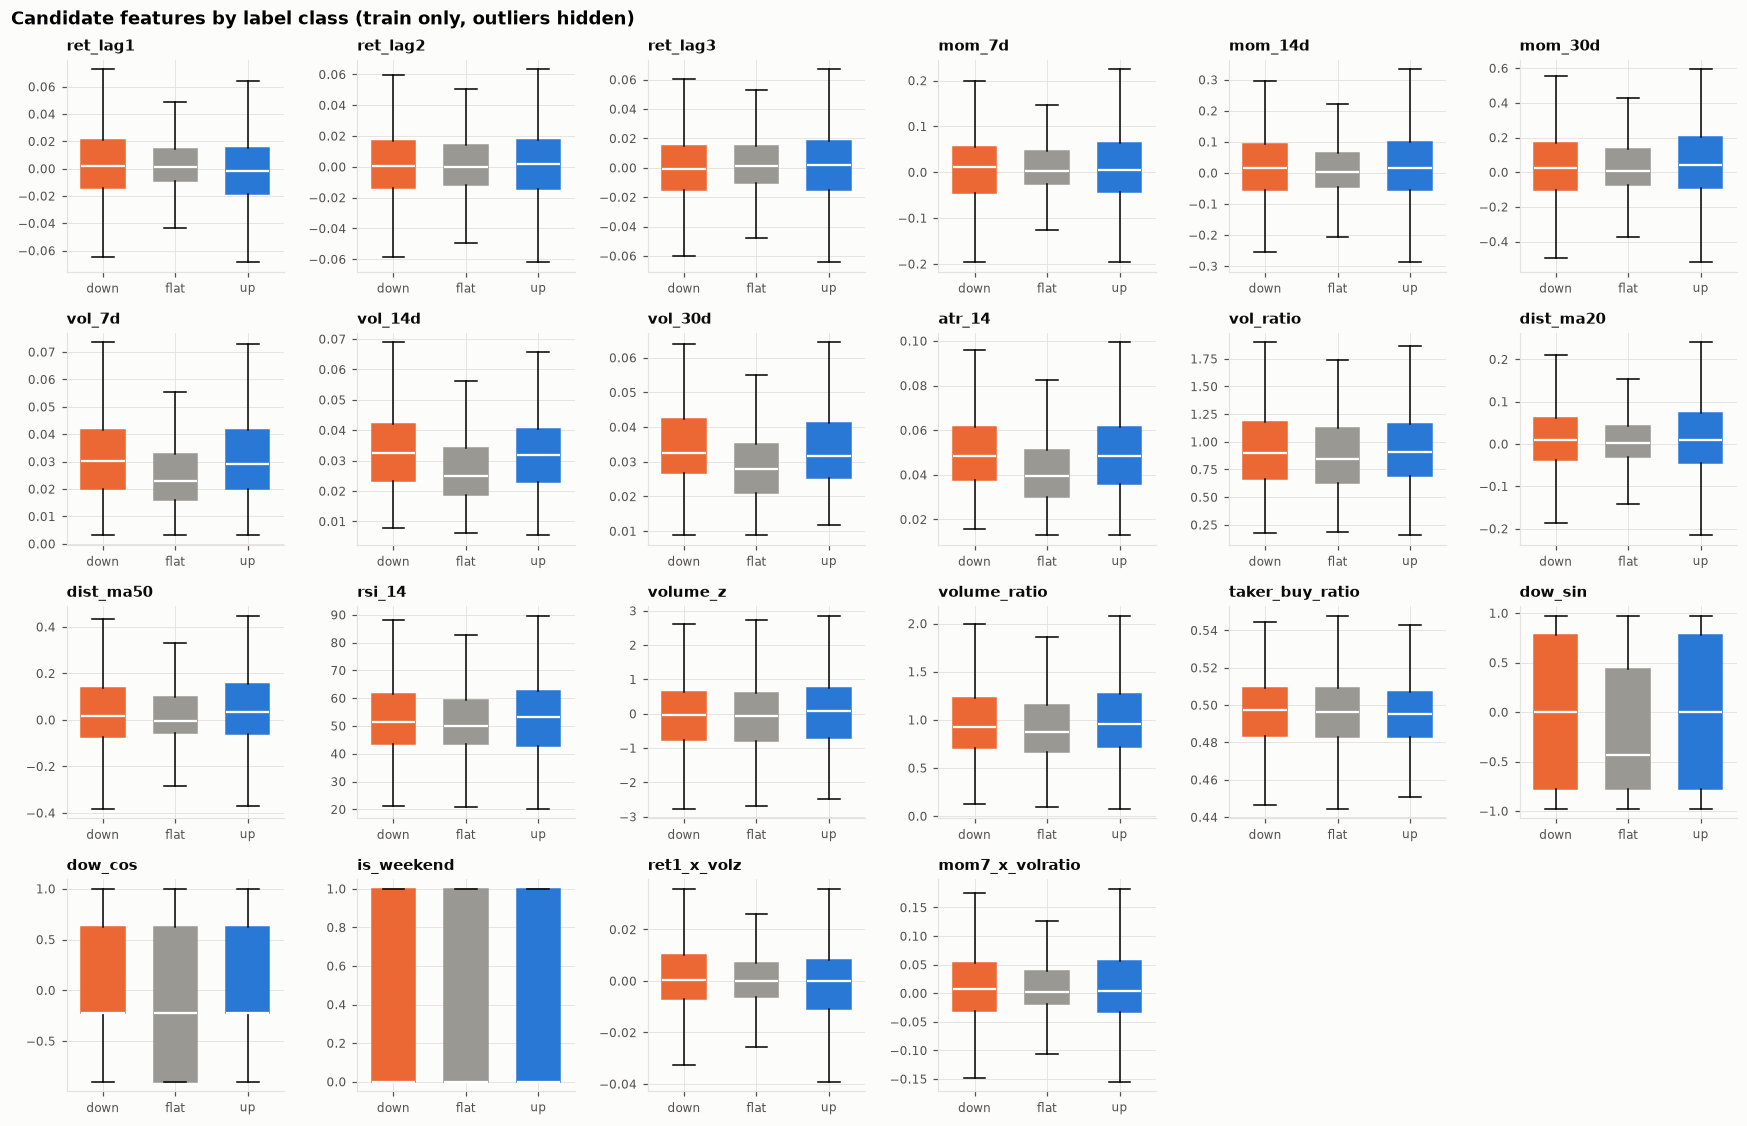

In [8]:
n_cols = 6
n_rows_grid = int(np.ceil(n_feats / n_cols))
fig, axes = plt.subplots(n_rows_grid, n_cols, figsize=(16, 2.6 * n_rows_grid))
classes = [DOWN, FLAT, UP]
for ax, col in zip(axes.flat, candidate_cols):
    data = [X_train.loc[y_train == c, col] for c in classes]
    parts = ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.6,
                       medianprops={"color": "white", "linewidth": 1.5})
    for patch, c in zip(parts["boxes"], classes):
        patch.set(facecolor=CLASS_COLORS[CLASS_NAMES[c]], edgecolor=CLASS_COLORS[CLASS_NAMES[c]])
    ax.set_xticks([1, 2, 3], [CLASS_NAMES[c] for c in classes])
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes.flat[n_feats:]:
    ax.set_visible(False)
fig.suptitle("Candidate features by label class (train only, outliers hidden)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
save(fig, "04_feature_vs_target")
plt.show()

The pattern is the one Phase 2 found: the **volatility** features separate *flat* from *up/down* (calm
days end flat, volatile days end with a move) but barely separate *up* from *down*. Almost no feature
shifts the up box relative to the down box — the direction signal is weak, which the tests below quantify.
The day-of-week panels tell the same story: *flat* days lean toward particular weekdays (quieter days end
flat more often), but up and down look alike. (`is_weekend` is binary, so its boxes span 0–1 and say
nothing visually; its relevance is measured in 5.3.)

### 5.3 Statistical relevance: ANOVA and mutual information

* **ANOVA F-test** — the standard test for a continuous feature vs. a categorical target: do the class
  means differ more than chance allows? Only sees *linear* (mean-shift) relationships.
* **Mutual information** — how much knowing the feature reduces uncertainty about the label; catches
  non-linear relationships too. MI is never exactly 0 on a finite sample, so each feature is compared with a
  **shuffled-label baseline**: the 95th percentile of the MI it scores against 20 random permutations of
  the label, i.e. what pure chance achieves.

A feature is treated as **clear noise** only if it fails *both*: ANOVA p > 0.05 **and** MI at or below
its shuffled baseline. Requiring both keeps features with either a linear or a non-linear signal, which
matters when every signal is weak.

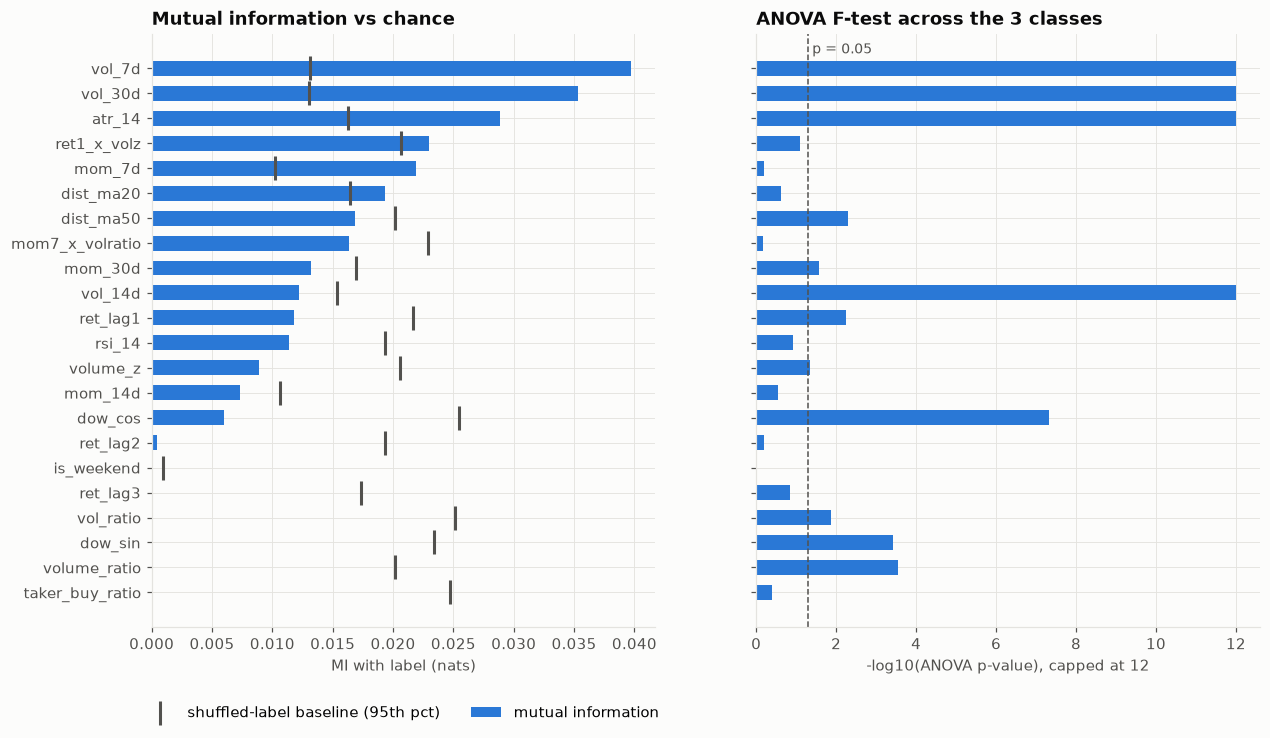

,anova_f,anova_p,mi,mi_noise,is_noise
vol_7d,38.1616,0.0000,0.0398,0.0131,False
vol_30d,45.4653,0.0000,0.0353,0.0130,False
atr_14,41.8183,0.0000,0.0289,0.0163,False
ret1_x_volz,2.4979,0.0825,0.0230,0.0206,False
mom_7d,0.4649,0.6283,0.0219,0.0102,False
dist_ma20,1.4544,0.2338,0.0194,0.0164,False
dist_ma50,5.3121,0.0050,0.0169,0.0201,False
mom7_x_volratio,0.4041,0.6676,0.0163,0.0229,True
mom_30d,3.6489,0.0262,0.0132,0.0169,False
vol_14d,49.3516,0.0000,0.0122,0.0154,False


In [9]:
scores = relevance(X_train, y_train)

fig, (ax_mi, ax_p) = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
y_pos = np.arange(len(scores))[::-1]
ax_mi.barh(y_pos, scores["mi"], color=BLUE, height=0.6, label="mutual information")
ax_mi.scatter(scores["mi_noise"], y_pos, marker="|", s=250, color=TEXT_SECONDARY, linewidths=2,
              label="shuffled-label baseline (95th pct)", zorder=3)
ax_mi.set(yticks=y_pos, yticklabels=scores.index, xlabel="MI with label (nats)")
ax_mi.set_title("Mutual information vs chance")
fig.legend(loc="lower center", bbox_to_anchor=(0.3, -0.03), ncol=2)

neg_log_p = -np.log10(scores["anova_p"].clip(lower=1e-12))
ax_p.barh(y_pos, neg_log_p, color=BLUE, height=0.6)
ax_p.axvline(-np.log10(0.05), color=TEXT_SECONDARY, linestyle="--", linewidth=1)
ax_p.text(-np.log10(0.05), y_pos[0] + 0.6, " p = 0.05", color=TEXT_SECONDARY, fontsize=9)
ax_p.set(xlabel="-log10(ANOVA p-value), capped at 12")
ax_p.set_title("ANOVA F-test across the 3 classes")
save(fig, "04_feature_relevance")
plt.show()

scores.round(4)

**Caveat — multiple testing.** With 22 features tested at α = 0.05, about one feature is expected to pass
ANOVA by chance alone, and the MI baseline has the same 5 % false-pass rate by construction. That is one
more reason to require *both* tests to fail before dropping, and to treat a lone significant result (e.g.
a day-of-week term) as a hypothesis for the modeling phase, not a finding.

### 5.4 The filter pass and the final selection

`select_features` applies the standard filter rules plus the noise rule, in this order, each step seeing only the
survivors of the one before:

1. **Near-constant** — one value in more than 95 % of rows.
2. **Low variance** — standard deviation ≈ 0. (The cutoff is tiny on purpose: these features live on
   very different scales — a daily return has std ≈ 0.03, RSI ≈ 10 — so a raw-std cutoff would drop
   small-unit features for their units, not their information.)
3. **Clear noise** — fails both tests in 5.3.
4. **Highly correlated pairs** — for each pair with |ρ| > 0.85, strongest first, drop the member with the
   lower MI. Once a feature is dropped its other pairs are skipped, so a cluster of three keeps one.

*Near-unique* attributes (IDs, names) do not occur in this feature set.

In [10]:
print("near-constant:", near_constant(X_train) or "none")
print("low variance: ", low_variance(X_train) or "none")

manifest = select_features(X_train, y_train)
selected = manifest["selected"]
print(f"\nkept {len(selected)} of {n_feats} candidates")
pd.DataFrame({"reason": manifest["dropped"]}).rename_axis("dropped feature")

near-constant: none
low variance:  none



kept 12 of 22 candidates


,reason
dropped feature,
mom7_x_volratio,noise: ANOVA p=0.67 and MI=0.0163 <= shuffled-...
rsi_14,noise: ANOVA p=0.12 and MI=0.0113 <= shuffled-...
mom_14d,noise: ANOVA p=0.28 and MI=0.0073 <= shuffled-...
ret_lag2,noise: ANOVA p=0.63 and MI=0.0004 <= shuffled-...
is_weekend,noise: ANOVA p=0.94 and MI=0.0000 <= shuffled-...
ret_lag3,noise: ANOVA p=0.14 and MI=0.0000 <= shuffled-...
taker_buy_ratio,noise: ANOVA p=0.40 and MI=0.0000 <= shuffled-...
mom_30d,"correlated with dist_ma50 (rho=0.93), lower MI"
vol_14d,"correlated with atr_14 (rho=0.91), lower MI"


In [11]:
print("selected:", selected)
residual = correlated_pairs(X_train[selected].corr(method="spearman"), CORR_THRESHOLD)
assert residual.empty, "no selected pair may exceed the correlation threshold"
print(f"OK: no remaining pair above |rho| = {CORR_THRESHOLD}")

selected: ['ret_lag1', 'mom_7d', 'vol_7d', 'vol_30d', 'atr_14', 'vol_ratio', 'dist_ma20', 'dist_ma50', 'volume_z', 'dow_sin', 'dow_cos', 'ret1_x_volz']
OK: no remaining pair above |rho| = 0.85


## 6 · Feature extraction: PCA

Selection keeps a subset of the original columns; **extraction** builds new axes that are combinations of
*all* of them. PCA picks the direction of greatest variance as the first component, the next
greatest (orthogonal to it) as the second, and so on.

The features are **standardized first**, which is the same as running PCA on the correlation matrix rather
than the covariance matrix — otherwise RSI (std ≈ 10) would dominate every component purely
because of its units. Fit on `train` only, on all 22 candidates.

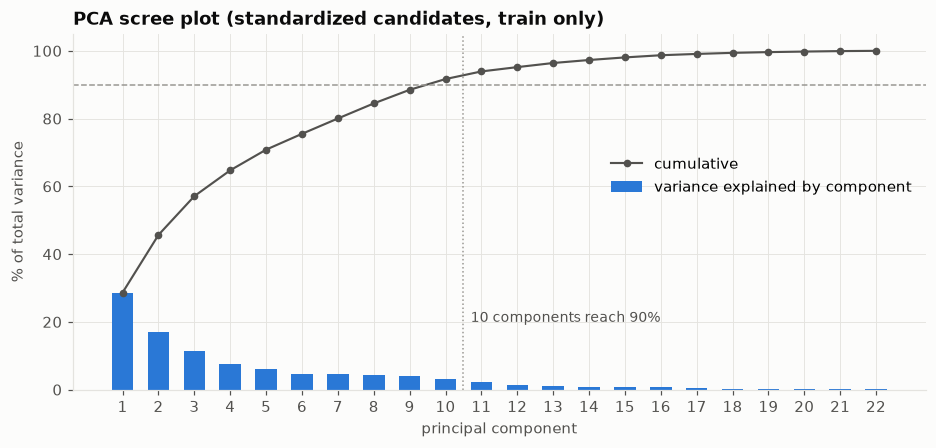

10 of 22 components explain 91.7% of the variance


In [12]:
pca_pipeline = fit_pca(X_train)
pca = pca_pipeline.named_steps["pca"]
full_pca = fit_pca(X_train, variance=None).named_steps["pca"]  # every component, for the scree plot
explained = 100 * full_pca.explained_variance_ratio_
k = pca.n_components_

fig, ax = plt.subplots(figsize=(10, 4.2))
pcs_idx = np.arange(1, len(explained) + 1)
ax.bar(pcs_idx, explained, color=BLUE, width=0.6, label="variance explained by component")
ax.plot(pcs_idx, np.cumsum(explained), color=TEXT_SECONDARY, marker="o", markersize=4, label="cumulative")
ax.axhline(90, color=NEUTRAL, linestyle="--", linewidth=1)
ax.axvline(k + 0.5, color=NEUTRAL, linestyle=":", linewidth=1)
ax.text(k + 0.7, 20, f"{k} components reach 90%", color=TEXT_SECONDARY, fontsize=9)
ax.set(xlabel="principal component", ylabel="% of total variance", xticks=pcs_idx,
       title="PCA scree plot (standardized candidates, train only)")
ax.legend(loc="center right", bbox_to_anchor=(1, 0.6))
save(fig, "04_pca_scree")
plt.show()

print(f"{k} of {n_feats} components explain {pca.explained_variance_ratio_.sum():.1%} of the variance")

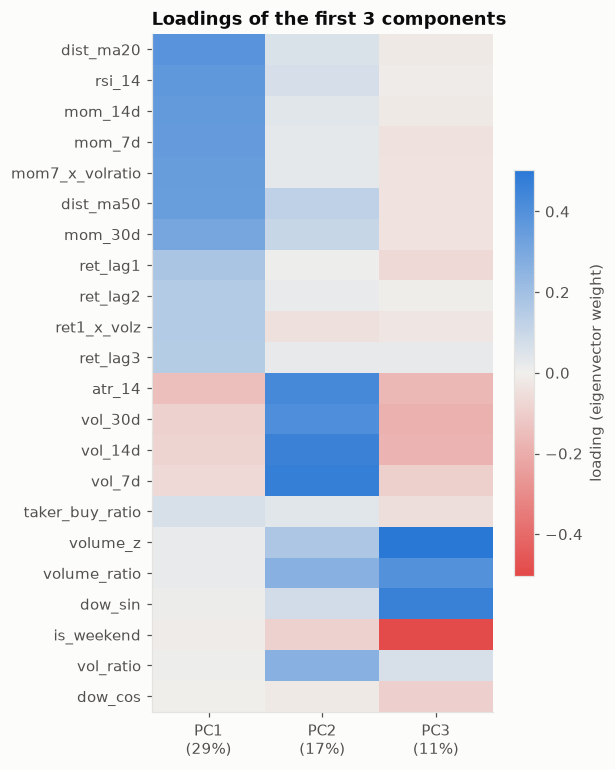

In [13]:
n_show = 3
loadings = pd.DataFrame(pca.components_[:n_show].T, index=candidate_cols,
                        columns=[f"PC{i + 1}" for i in range(n_show)])
order = loadings["PC1"].abs().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(5, 8))
lim = np.abs(loadings.to_numpy()).max()
im = ax.imshow(loadings.loc[order], cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(n_show), [f"PC{i + 1}\n({100 * r:.0f}%)" for i, r in
                              enumerate(pca.explained_variance_ratio_[:n_show])])
ax.set_yticks(range(n_feats), order)
ax.grid(False)
ax.set_title("Loadings of the first 3 components")
fig.colorbar(im, ax=ax, shrink=0.6, label="loading (eigenvector weight)")
save(fig, "04_pca_loadings")
plt.show()

**Reading it.** The eigenvectors are the directions; the eigenvalues (the % in each label) say how much
variance lies along them. The first three components recover, without being told, the three
blocks seen in the heatmap:

* **PC1 (≈29 %) = trend** — `dist_ma20`, `rsi_14`, `mom_*`, `dist_ma50` all load together: the single biggest
  source of redundancy is "is the price above its recent past", measured six ways.
* **PC2 (≈17 %) = volatility** — `vol_*` and `atr_14`.
* **PC3 (≈11 %) = activity / calendar** — `volume_z`, `volume_ratio`, `dow_sin` against `is_weekend`:
  busy weekdays vs quiet weekends.

These are the same clusters the correlation filter thinned out, which is a useful cross-check that the two
methods agree on where the redundancy is.

Needing about half the original dimensions to reach 90 % says the candidates are *not* massively redundant
overall once the volatility block is accounted for — the features mostly measure different things, they
just measure them weakly.

**Trade-off.** The PCA variant is more compact and uses information from every candidate, but a
model trained on `pc3` cannot be explained in trader terms. The selected set stays the main input; the PCA
variant is persisted so the modeling phase can compare the two head-to-head.

## 7 · Persist model-ready data

* `data/processed/btcusdt_1D_{train,val,test}.parquet` — **all** candidate features + `label`. The model
  reads only the selected columns (via the manifest), so a later re-selection never needs to regenerate data.
* `data/processed/btcusdt_1D_pca_{train,val,test}.parquet` — the PCA variant (`pc1..pcK` + `label`),
  transformed with the train-fitted scaler and components.
* `src/features/selected_features.json` — **tracked in git**: kept features, every dropped feature with
  its reason, and the selection parameters. `src/modeling/train.py` loads `FEATURE_COLUMNS` from it.

In [14]:
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
for split, df in [("train", train), ("val", val), ("test", test)]:
    path = config.PROCESSED_DIR / f"{config.SYMBOL.lower()}_1D_{split}.parquet"
    df.to_parquet(path)
    pca_df = pca_transform(pca_pipeline, df[candidate_cols]).assign(label=df["label"])
    pca_path = config.PROCESSED_DIR / f"{config.SYMBOL.lower()}_1D_pca_{split}.parquet"
    pca_df.to_parquet(pca_path)
    print(f"saved {path.relative_to(ROOT)} and {pca_path.name}  ({len(df):,} rows)")

save_manifest(manifest)
print(f"saved {MANIFEST_PATH.relative_to(ROOT)}  ({len(selected)} selected features)")

saved data\processed\btcusdt_1D_train.parquet and btcusdt_1D_pca_train.parquet  (1,954 rows)
saved data\processed\btcusdt_1D_val.parquet and btcusdt_1D_pca_val.parquet  (417 rows)
saved data\processed\btcusdt_1D_test.parquet and btcusdt_1D_pca_test.parquet  (420 rows)
saved src\features\selected_features.json  (12 selected features)


## Summary -> inputs for Modeling

| Decision | Value |
|---|---|
| Label | 1D horizon, θ = 1% (UP / FLAT / DOWN) — unchanged |
| Split | Chronological 70/15/15, embargo = 1 row at each boundary; done *before* selection |
| Candidates | 22: true lags, momentum, volatility, ATR, trend/RSI, relative volume, taker-buy, day-of-week, 2 interactions (`log_volume` removed on domain grounds) |
| Selection (train only) | near-constant → low variance → noise (fails ANOVA *and* MI) → Spearman \|ρ\| > 0.85, keep higher MI |
| Selected features | listed in `src/features/selected_features.json` (printed in 5.4) |
| Extraction | Standardized PCA on all candidates; components for 90 % variance persisted as a comparison variant |
| Output | `data/processed/btcusdt_1D_{,pca_}{train,val,test}.parquet` + the manifest |

Next phase (Modeling): train on the selected features, compare against the PCA variant and the baselines
from `03_eda.ipynb` on `val`, and keep `test` untouched until the final evaluation.